#### Import Necessary Libraries

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [6]:
df = pd.read_csv('/Users/amaree/Desktop/Masters Dissertation Dataset/Nigeria Road Crashes Report Cleaned.csv')

In [9]:
df.head()

,state,year,quarter,fatal,serious,minor,total_cases,number_injured,number_killed,total_casualty,people_involved,spv,upd,tbt,mdv,bfl,ovl,dot,wot,dgd,brd,rtv,obs,sos,dad,pwr,ftq,slv,others,common_cause_total,source_cause_total,excl_or_new_cause_count
0,Abia,2020,Q2,5,12,1,18,44,8,52,92,10,0,4,0,3,0,0,1,0,0,2,0,0,0,0,0,0,0,20,20,0
1,Adamawa,2020,Q2,9,37,2,48,115,17,132,226,36,0,0,0,0,0,0,5,1,0,0,10,0,0,0,0,0,0,52,52,0
2,Akwa Ibom,2020,Q2,1,11,6,18,20,1,21,67,5,0,0,0,3,0,0,1,6,1,0,0,0,0,0,0,0,0,16,16,0
3,Anambra,2020,Q2,16,28,9,53,92,22,114,263,20,0,2,1,9,0,0,3,2,0,2,0,0,0,0,0,2,0,41,41,0
4,Bauchi,2020,Q2,32,46,0,78,313,55,368,501,28,1,10,1,0,1,1,20,13,3,7,2,0,0,0,0,1,0,88,88,0


In [11]:
df.shape

(851, 32)

In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 851 entries, 0 to 850
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype
---  ------                   --------------  -----
 0   state                    851 non-null    str  
 1   year                     851 non-null    int64
 2   quarter                  851 non-null    str  
 3   fatal                    851 non-null    int64
 4   serious                  851 non-null    int64
 5   minor                    851 non-null    int64
 6   total_cases              851 non-null    int64
 7   number_injured           851 non-null    int64
 8   number_killed            851 non-null    int64
 9   total_casualty           851 non-null    int64
 10  people_involved          851 non-null    int64
 11  spv                      851 non-null    int64
 12  upd                      851 non-null    int64
 13  tbt                      851 non-null    int64
 14  mdv                      851 non-null    int64
 15  bfl              

In [15]:
df.isnull().sum()

state                      0
year                       0
quarter                    0
fatal                      0
serious                    0
minor                      0
total_cases                0
number_injured             0
number_killed              0
total_casualty             0
people_involved            0
spv                        0
upd                        0
tbt                        0
mdv                        0
bfl                        0
ovl                        0
dot                        0
wot                        0
dgd                        0
brd                        0
rtv                        0
obs                        0
sos                        0
dad                        0
pwr                        0
ftq                        0
slv                        0
others                     0
common_cause_total         0
source_cause_total         0
excl_or_new_cause_count    0
dtype: int64

In [17]:
df.columns = (
    df.columns
      .str.strip()
      .str.lower()
      .str.replace(" ", "_")
)

df.columns.tolist()

['state',
 'year',
 'quarter',
 'fatal',
 'serious',
 'minor',
 'total_cases',
 'number_injured',
 'number_killed',
 'total_casualty',
 'people_involved',
 'spv',
 'upd',
 'tbt',
 'mdv',
 'bfl',
 'ovl',
 'dot',
 'wot',
 'dgd',
 'brd',
 'rtv',
 'obs',
 'sos',
 'dad',
 'pwr',
 'ftq',
 'slv',
 'others',
 'common_cause_total',
 'source_cause_total',
 'excl_or_new_cause_count']

The dataset contains 851 state-quarter observations covering 37 geographical units (36 states and the FCT) from Q2 2020 to Q4 2025. No missing values were identified in the final cleaned dataset. This provides a complete panel for the exploratory analysis without requiring imputation of the original variables.

#### Numerical Quarter Variable

In [24]:
# quarter map

quarter_codes = {
    "Q1": 1,
    "Q2": 2,
    "Q3": 3,
    "Q4": 4
}

df["quarter_code"] = df["quarter"].replace(quarter_codes)

In [26]:
df[["quarter", "quarter_code"]].drop_duplicates().sort_values("quarter_code")

,quarter,quarter_code
111,Q1,1
0,Q2,2
37,Q3,3
74,Q4,4


In [28]:
# create periods

df["period"] = pd.PeriodIndex(
    df["year"].astype(str) + "Q" + df["quarter_code"].astype(str),
    freq="Q"
)

In [30]:
df[["year", "quarter", "quarter_code", "period"]].head(10)

,year,quarter,quarter_code,period
0,2020,Q2,2,2020Q2
1,2020,Q2,2,2020Q2
2,2020,Q2,2,2020Q2
3,2020,Q2,2,2020Q2
4,2020,Q2,2,2020Q2
5,2020,Q2,2,2020Q2
6,2020,Q2,2,2020Q2
7,2020,Q2,2,2020Q2
8,2020,Q2,2,2020Q2
9,2020,Q2,2,2020Q2


In [32]:
# Sort

df = df.sort_values(
    ["state", "year", "quarter_code"]
).reset_index(drop=True)

In [34]:
df[df["state"] == "Abia"][
    ["state", "year", "quarter", "quarter_code", "period", "total_cases"]
].head(10)

,state,year,quarter,quarter_code,period,total_cases
0,Abia,2020,Q2,2,2020Q2,18
1,Abia,2020,Q3,3,2020Q3,28
2,Abia,2020,Q4,4,2020Q4,30
3,Abia,2021,Q1,1,2021Q1,44
4,Abia,2021,Q2,2,2021Q2,21
5,Abia,2021,Q3,3,2021Q3,20
6,Abia,2021,Q4,4,2021Q4,21
7,Abia,2022,Q1,1,2022Q1,33
8,Abia,2022,Q2,2,2022Q2,29
9,Abia,2022,Q3,3,2022Q3,24


In [45]:
qtr_crashes = (
    df.groupby(["year", "quarter", "quarter_code"])["total_cases"]
      .sum()
      .reset_index(name="total_crashes")
      .sort_values(by=["year", "quarter_code"])
)

qtr_crashes["period_label"] = (
    qtr_crashes["year"].astype(str)
    + "-"
    + qtr_crashes["quarter"]
)

qtr_crashes

,year,quarter,quarter_code,total_crashes,period_label
0,2020,Q2,2,2080,2020-Q2
1,2020,Q3,3,3066,2020-Q3
2,2020,Q4,4,3313,2020-Q4
3,2021,Q1,1,3301,2021-Q1
4,2021,Q2,2,3185,2021-Q2
5,2021,Q3,3,3134,2021-Q3
6,2021,Q4,4,3407,2021-Q4
7,2022,Q1,1,3345,2022-Q1
8,2022,Q2,2,3282,2022-Q2
9,2022,Q3,3,3412,2022-Q3


In [47]:
state_summary = (
    df.groupby("state", as_index=False)
      .agg(
          average_crashes=("total_cases", "mean"),
          total_crashes=("total_cases", "sum")
      )
      .sort_values("average_crashes", ascending=False)
)

In [51]:
%pip install plotly

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 136.1 kB/s  0:01:05m0:00:0200:04
Note: you may need to restart the kernel to use updated packages.


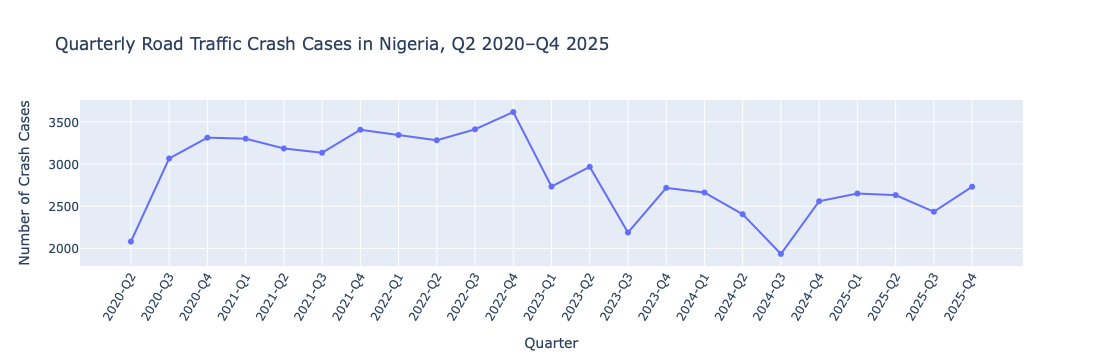

In [55]:
import plotly.express as px

fig = px.line(
    qtr_crashes,
    x="period_label",
    y="total_crashes",
    markers=True,
    title="Quarterly Road Traffic Crash Cases in Nigeria, Q2 2020–Q4 2025"
)

fig.update_layout(
    xaxis_title="Quarter",
    yaxis_title="Number of Crash Cases",
    xaxis_tickangle=-60
)

fig.update_traces(
    hovertemplate="<b>%{x}</b><br>Crash Cases: %{y:,}<extra></extra>"
)

fig.show()

### Interpretation

Quarterly road traffic crash cases showed noticeable changes throughout the study period. The number of recorded cases generally increased between 2020 and 2022, reaching a peak of 3,617 cases in Q4 2022. This was followed by an overall decline during 2023 and 2024, with the lowest number of 1,933 cases recorded in Q3 2024. Crash cases increased again in Q4 2024 and remained relatively stable throughout 2025.

These changes show that road traffic crash cases did not follow a consistent linear trend over the study period. This highlights the importance of including historical observations and lagged variables when developing the forecasting models to account for changes in crash patterns over time.

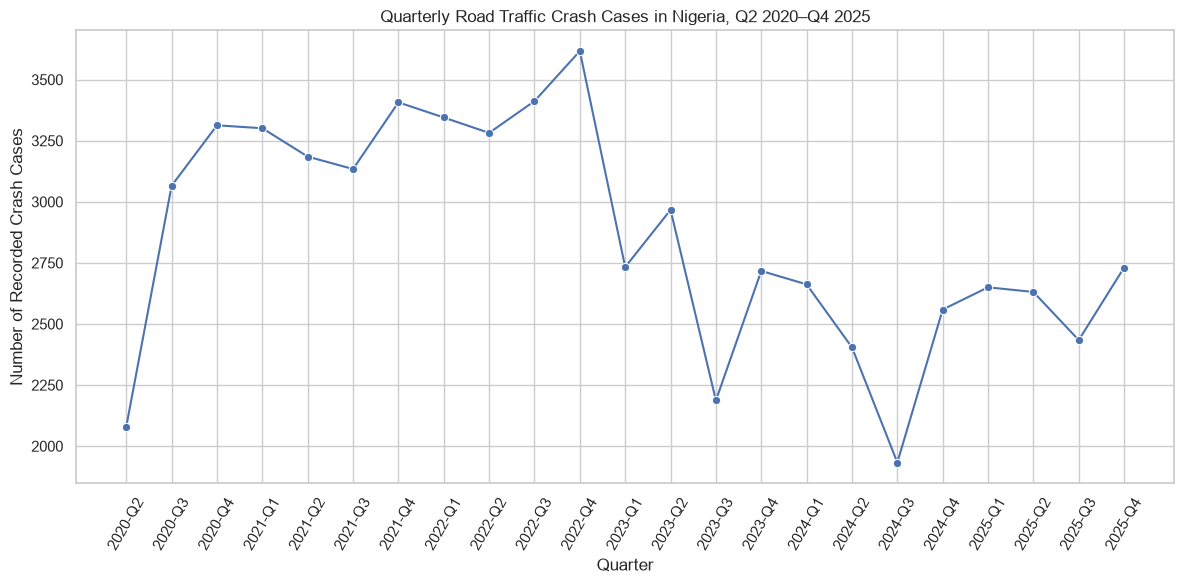

In [40]:
plt.figure(figsize=(12, 6))

sns.lineplot(
    data=national_trend,
    x="period_label",
    y="total_crashes",
    marker="o"
)

plt.title("Quarterly Road Traffic Crash Cases in Nigeria, Q2 2020–Q4 2025")
plt.xlabel("Quarter")
plt.ylabel("Number of Recorded Crash Cases")
plt.xticks(rotation=60)

plt.tight_layout()
plt.show()

### Average Quartely Plot

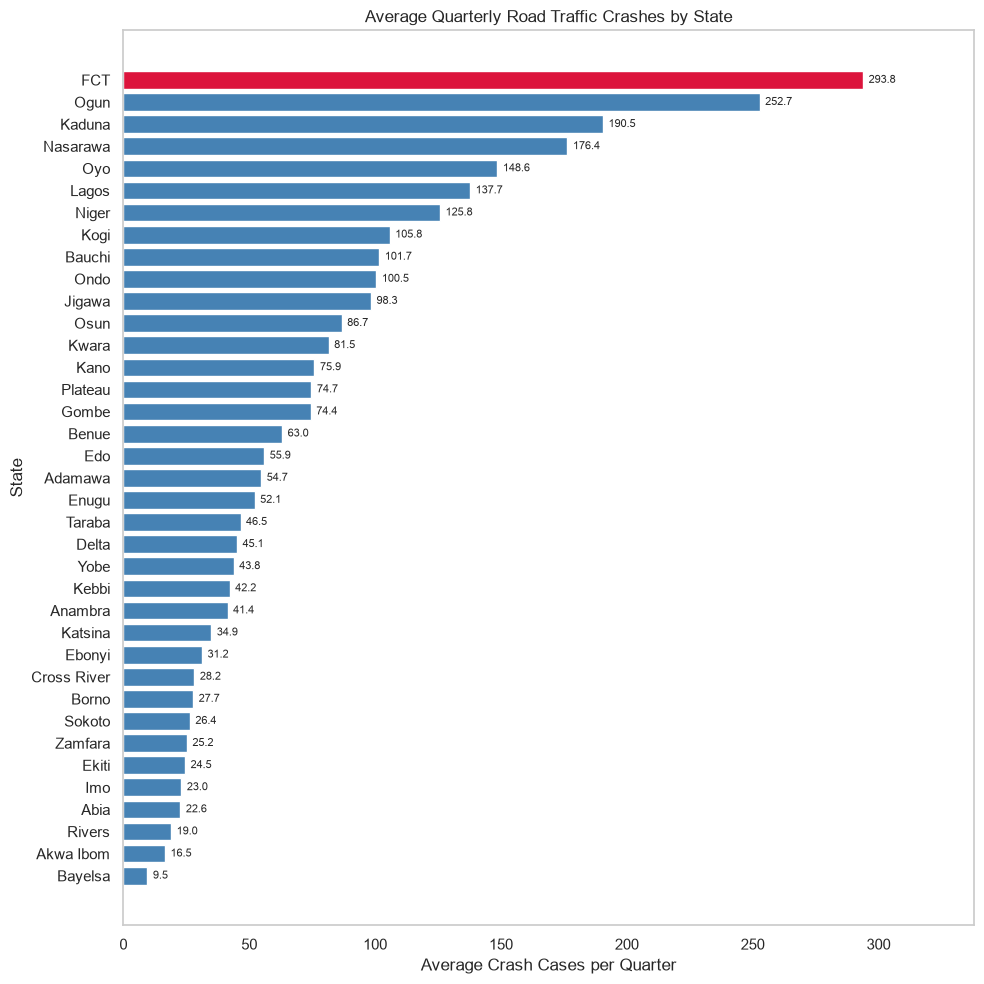

In [63]:
# maximum average
highest_avg = state_summary["average_crashes"].max()


bar_colours = [
    "crimson" if value == highest_avg else "steelblue"
    for value in state_summary["average_crashes"]
]

fig, ax = plt.subplots(figsize=(10, 10))

bars = ax.barh(
    state_summary["state"],
    state_summary["average_crashes"],
    color=bar_colours
)

ax.bar_label(
    bars,
    fmt="%.1f",
    padding=4,
    fontsize=8
)

ax.set_title("Average Quarterly Road Traffic Crashes by State")
ax.set_xlabel("Average Crash Cases per Quarter")
ax.set_ylabel("State")
ax.invert_yaxis()

ax.set_xlim(0, highest_avg * 1.15)

ax.grid(False)

plt.tight_layout()
plt.show()

#### Interpretation

The results show considerable differences in the average number of quarterly road traffic crash cases across Nigerian states. The FCT recorded the highest average number of cases per quarter, followed by Ogun State, while several other states recorded much lower averages.

These differences show that road traffic crash frequency varies considerably across geographical locations. This highlights the importance of retaining state-level information in the forecasting models, as historical crash patterns and the number of recorded cases differ between states.

#### State differences plot

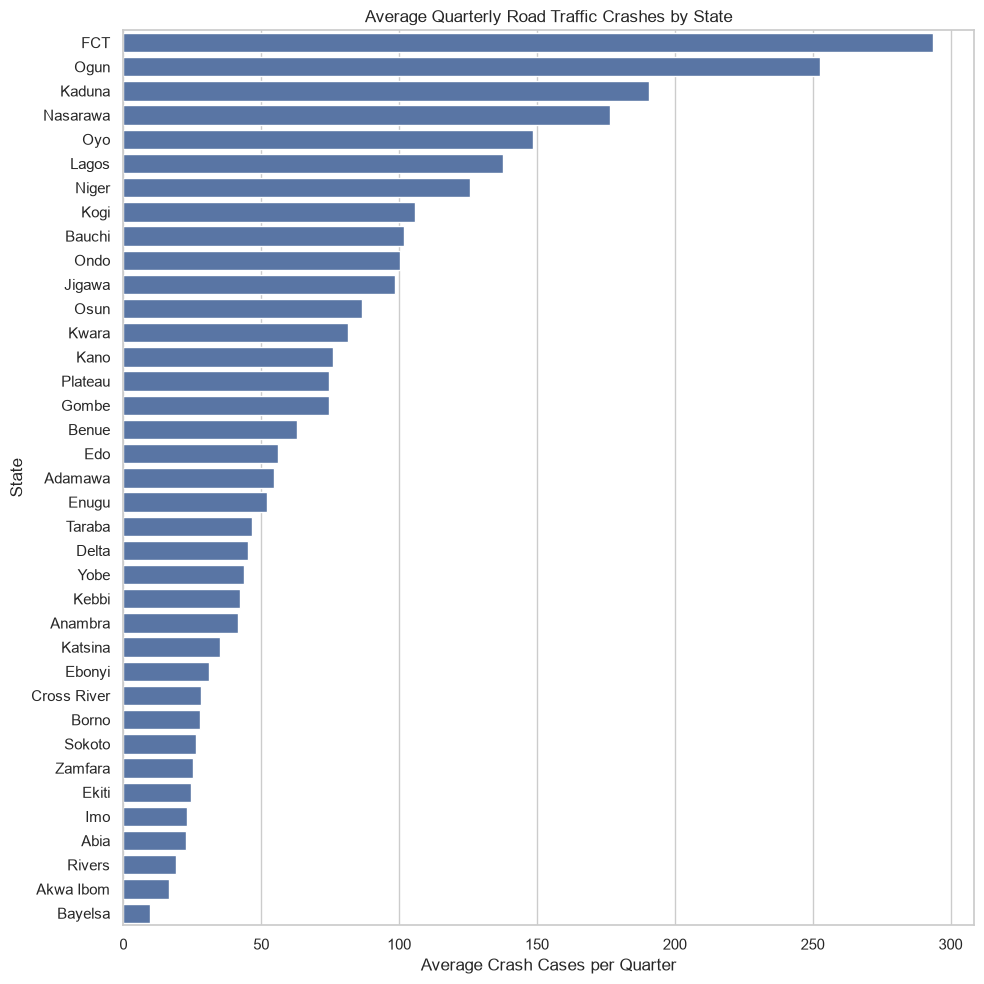

In [57]:
plt.figure(figsize=(10, 10))

sns.barplot(
    data=state_summary,
    y="state",
    x="average_crashes"
)

plt.title("Average Quarterly Road Traffic Crashes by State")
plt.xlabel("Average Crash Cases per Quarter")
plt.ylabel("State")

plt.tight_layout()
plt.show()

#### causative factors

In [48]:
cause_labels = {
    "spv": "Speed Violation",
    "upd": "Phone While Driving",
    "tbt": "Tyre Burst",
    "mdv": "Mechanically Deficient Vehicle",
    "bfl": "Brake Failure",
    "ovl": "Overloading",
    "dot": "Dangerous Overtaking",
    "wot": "Wrongful Overtaking",
    "dgd": "Dangerous Driving",
    "brd": "Bad Road",
    "rtv": "Route Violation",
    "obs": "Road Obstruction",
    "sos": "Sleeping on Steering",
    "dad": "Alcohol/Drug Influence",
    "pwr": "Poor Weather",
    "ftq": "Fatigue",
    "slv": "Sign Light Violation",
    "others": "Others"
}

In [50]:
cause_totals = (
    df[list(cause_labels.keys())]
      .sum()
      .sort_values(ascending=False)
      .rename(index=cause_labels)
)

cause_totals

Speed Violation                   49193
Sign Light Violation               5143
Wrongful Overtaking                4922
Dangerous Driving                  4485
Tyre Burst                         4352
Route Violation                    3757
Others                             3566
Brake Failure                      3360
Mechanically Deficient Vehicle     2619
Overloading                         985
Road Obstruction                    980
Fatigue                             709
Bad Road                            585
Sleeping on Steering                396
Dangerous Overtaking                352
Alcohol/Drug Influence              238
Phone While Driving                 202
Poor Weather                         64
dtype: int64

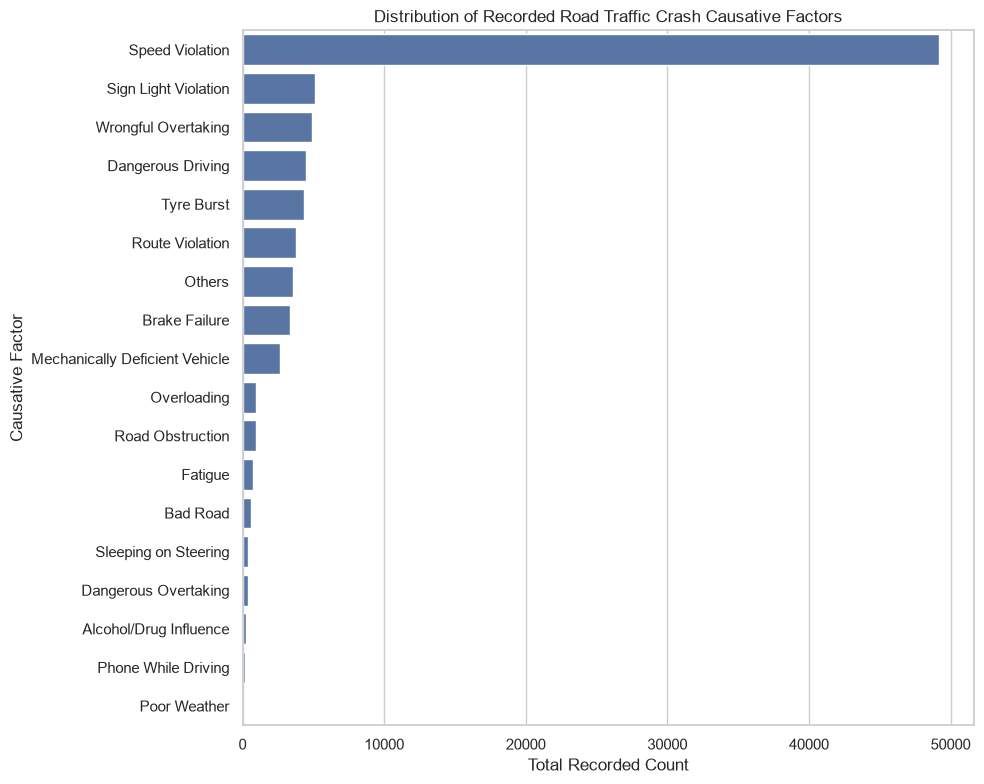

In [52]:
plt.figure(figsize=(10, 8))

sns.barplot(
    x=cause_totals.values,
    y=cause_totals.index
)

plt.title("Distribution of Recorded Road Traffic Crash Causative Factors")
plt.xlabel("Total Recorded Count")
plt.ylabel("Causative Factor")

plt.tight_layout()
plt.show()

### Target Variable

In [57]:
df["total_cases"].describe()

count    851.000000
mean      77.262045
std       70.363548
min        1.000000
25%       28.000000
50%       55.000000
75%      102.000000
max      538.000000
Name: total_cases, dtype: float64

#### Interpretation

The target variable, `total_cases`, recorded an average of 77.26 crash cases per state-quarter, with a median of 55. The standard deviation of 70.36 shows considerable variation in the number of recorded crash cases across the observations. Crash counts ranged from a minimum of 1 to a maximum of 538 cases.

The higher mean compared with the median, alongside the wide range of recorded values, suggests that the distribution was influenced by a smaller number of observations with relatively high crash counts.

In [59]:
# skewness

df["total_cases"].skew()

2.055482426900866

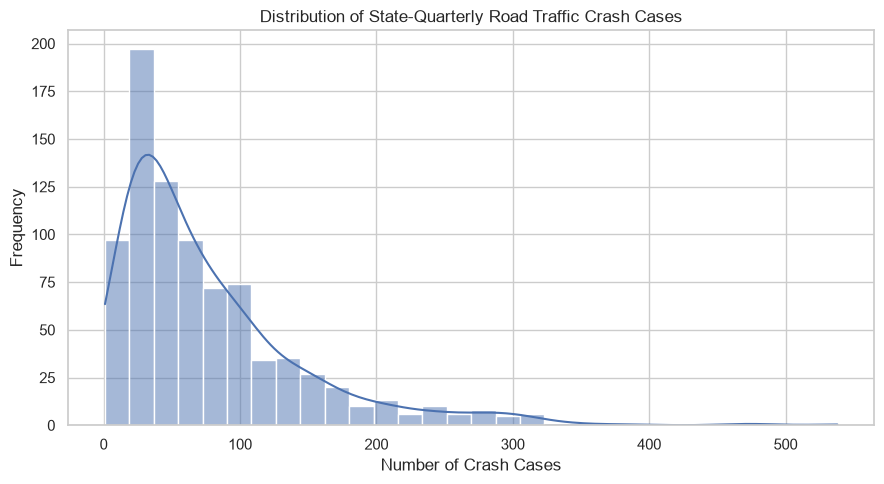

In [65]:
#histogram

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="total_cases",
    bins=30,
    kde=True
)

plt.title("Distribution of State-Quarterly Road Traffic Crash Cases")
plt.xlabel("Number of Crash Cases")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

#### Interpretation

The distribution of total road traffic crash cases was positively skewed, with a skewness value of 2.055. The histogram shows that most state-quarter observations recorded low to moderate crash counts, while a smaller number had considerably higher values, resulting in a long right tail.

This is also reflected in the mean of 77.26 being higher than the median of 55, suggesting that observations with higher crash counts increased the overall average.

This distribution will be considered when evaluating forecasting performance, particularly when interpreting RMSE, as this metric gives greater weight to larger prediction errors.

### Distribution of Crashes Plot

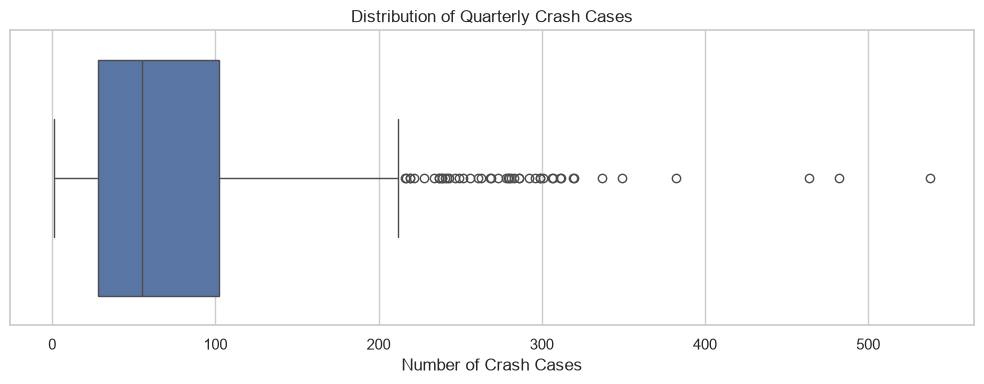

In [67]:
# boxplot

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="total_cases"
)

plt.title("Distribution of Quarterly Crash Cases")
plt.xlabel("Number of Crash Cases")

plt.tight_layout()
plt.show()

#### Interpretation

The box plot shows several observations above the upper whisker, indicating that some state-quarter observations recorded unusually high crash counts compared with the overall distribution.

However, these observations were not automatically removed, as values identified as statistical outliers do not necessarily represent errors in the dataset.

The state-level analysis also showed considerable differences in crash frequency across Nigeria, suggesting that some of the higher values may reflect actual crash patterns in states with consistently higher numbers of recorded cases.

For this reason, the observations were retained for modelling rather than being excluded solely because they were identified as outliers in the box plot.

In [65]:
df.nlargest(20, "total_cases")[
    ["state", "year", "quarter", "total_cases"]
]

,state,year,quarter,total_cases
330,FCT,2022,Q2,538
332,FCT,2022,Q4,482
331,FCT,2022,Q3,464
333,FCT,2023,Q1,382
335,FCT,2023,Q3,349
625,Ogun,2021,Q2,337
334,FCT,2023,Q2,320
329,FCT,2022,Q1,319
324,FCT,2020,Q4,312
323,FCT,2020,Q3,311


### Correlation Analysis

#### Descriptive

In [69]:
outcome_vars = [
    "total_cases",
    "fatal",
    "serious",
    "minor",
    "number_killed",
    "number_injured",
    "total_casualty",
    "people_involved"
]

outcome_corr = df[outcome_vars].corr()

outcome_corr.round(2)

,total_cases,fatal,serious,minor,number_killed,number_injured,total_casualty,people_involved
total_cases,1.00,0.87,0.98,0.77,0.70,0.87,0.86,0.93
fatal,0.87,1.00,0.81,0.52,0.90,0.91,0.93,0.94
serious,0.98,0.81,1.00,0.68,0.65,0.86,0.85,0.90
minor,0.77,0.52,0.68,1.00,0.31,0.44,0.43,0.62
number_killed,0.70,0.90,0.65,0.31,1.00,0.87,0.90,0.84
number_injured,0.87,0.91,0.86,0.44,0.87,1.00,1.00,0.95
total_casualty,0.86,0.93,0.85,0.43,0.90,1.00,1.00,0.95
people_involved,0.93,0.94,0.90,0.62,0.84,0.95,0.95,1.00


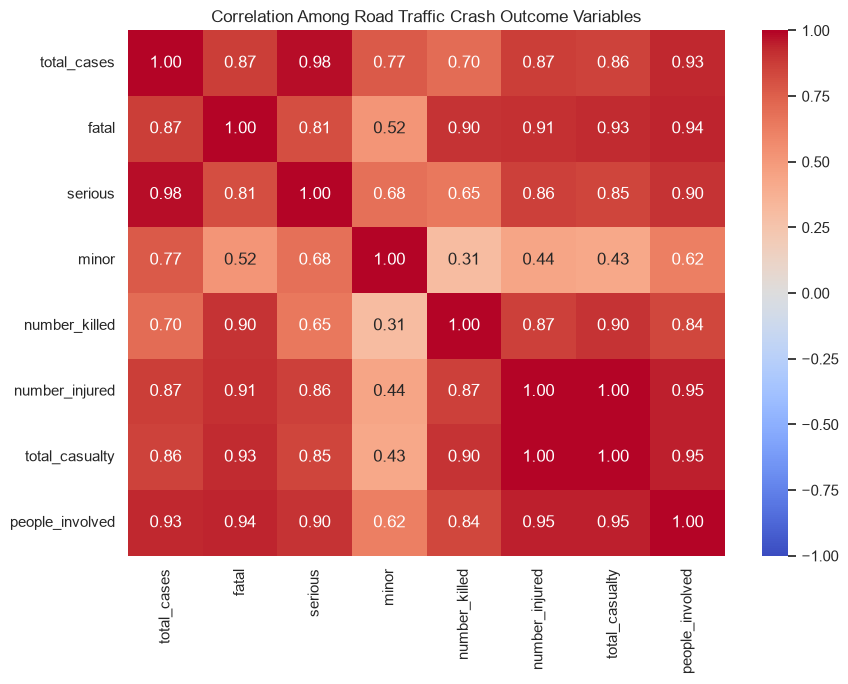

In [73]:
plt.figure(figsize=(9, 7))

sns.heatmap(
    outcome_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Among Road Traffic Crash Outcome Variables")

plt.tight_layout()
plt.show()

#### Interpretation

The results show strong positive correlations between total road traffic crash cases and several crash-related variables. The strongest correlation was observed with serious crashes (r = 0.98), followed by people involved (r = 0.93), fatal crashes (r = 0.87), number injured (r = 0.87), total casualties (r = 0.86), minor crashes (r = 0.77) and number killed (r = 0.70).

Although these relationships are useful for understanding the dataset, the variables were not considered suitable as predictors of total_cases when using values from the same quarter.

This is particularly important for fatal, serious and minor crash cases, as these variables contribute directly to the total number of recorded crashes. Including their current-quarter values in the forecasting models would introduce target leakage by providing information about the outcome being predicted.

For this reason, the correlations were used to describe relationships within the dataset rather than to determine which current-quarter variables should be included as forecasting features.

In [77]:
### corr btw causative factors and crash frequency

cause_vars = [
    "spv", "upd", "tbt", "mdv", "bfl", "ovl",
    "dot", "wot", "dgd", "brd", "rtv", "obs",
    "sos", "dad", "pwr", "ftq", "slv", "others"
]

In [79]:
cause_corr = (
    df[cause_vars + ["total_cases"]]
    .corr()["total_cases"]
    .drop("total_cases")
    .sort_values(ascending=False)
)

cause_corr

spv       0.899494
rtv       0.794006
dgd       0.670186
tbt       0.668078
wot       0.574999
slv       0.574317
others    0.427312
mdv       0.392091
bfl       0.387271
ftq       0.310419
ovl       0.296898
dot       0.293982
obs       0.269530
upd       0.260424
dad       0.223584
brd       0.197992
sos       0.174298
pwr       0.167614
Name: total_cases, dtype: float64

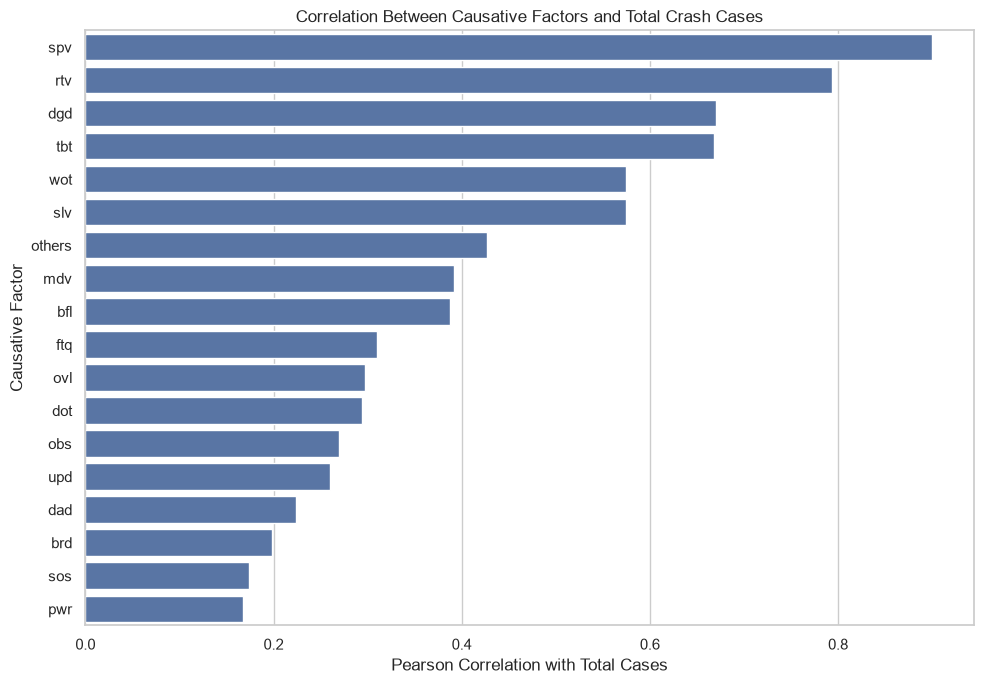

In [81]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=cause_corr.values,
    y=cause_corr.index
)

plt.title("Correlation Between Causative Factors and Total Crash Cases")
plt.xlabel("Pearson Correlation with Total Cases")
plt.ylabel("Causative Factor")

plt.tight_layout()
plt.show()

#### Interpretation

The results show positive correlations between several recorded crash causative factors and total road traffic crash cases. Speed violation (SPV) recorded the strongest correlation (r = 0.90), followed by route violation (RTV, r = 0.79), dangerous driving (DGD, r = 0.67), tyre burst (TBT, r = 0.67), wrongful overtaking (WOT, r = 0.57) and sign/light violation (SLV, r = 0.57).

Speed violation therefore showed the strongest association with total crash frequency among the recorded causative factors. However, these correlations only indicate statistical relationships within the dataset and do not provide evidence that the factors directly caused the recorded crashes.

For the forecasting models, lagged values of these factors were used instead of their current-quarter values. This ensured that the models relied only on historical information available before the quarter being predicted, reducing the risk of target leakage.

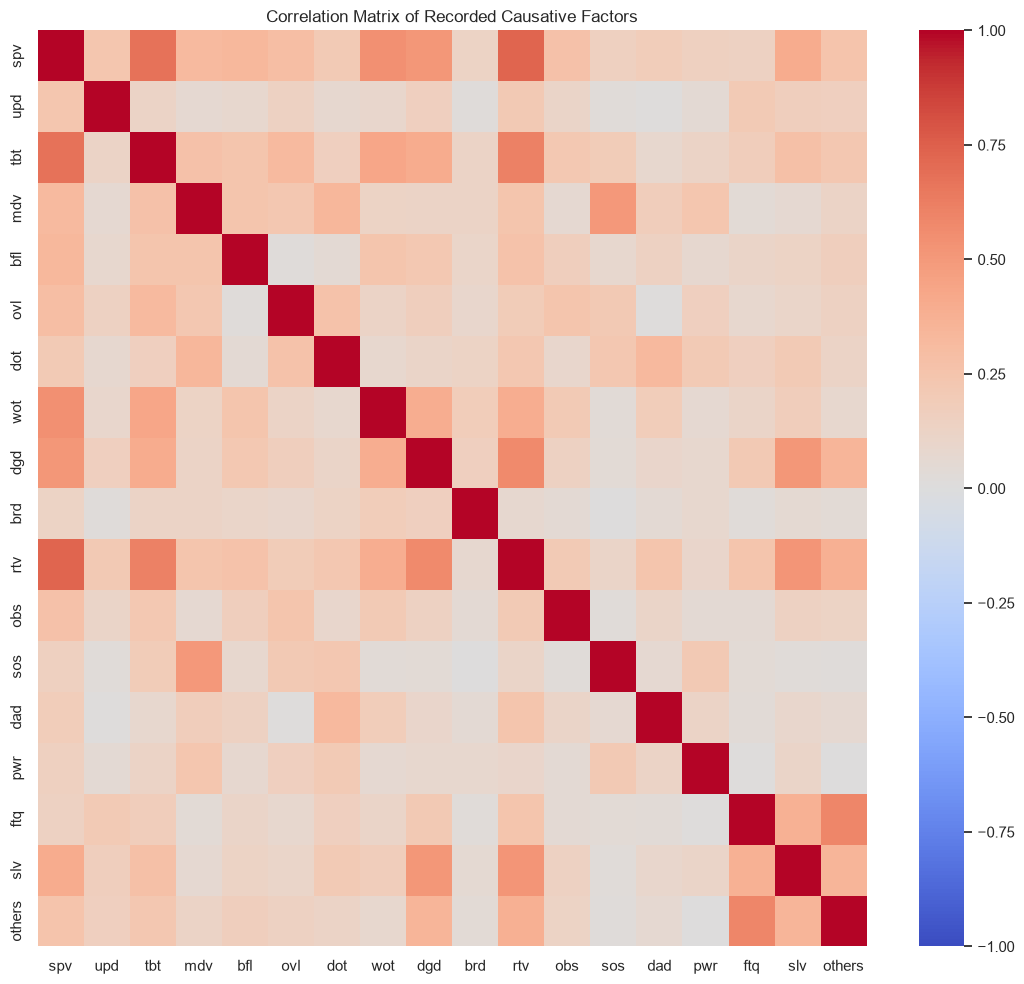

In [89]:
# corr among the causative factors 

cause_matrix = df[cause_vars].corr()

plt.figure(figsize=(11, 10))

sns.heatmap(
    cause_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Recorded Causative Factors")

plt.tight_layout()
plt.show()

In [91]:
corr_pairs = (
    cause_matrix
    .where(
        np.triu(
            np.ones(cause_matrix.shape),
            k=1
        ).astype(bool)
    )
    .stack()
    .reset_index()
)

corr_pairs.columns = [
    "variable_1",
    "variable_2",
    "correlation"
]

corr_pairs["absolute_correlation"] = (
    corr_pairs["correlation"].abs()
)

corr_pairs.sort_values(
    "absolute_correlation",
    ascending=False
).head(15)

,variable_1,variable_2,correlation,absolute_correlation
10,spv,rtv,0.729421,0.729421
2,spv,tbt,0.676263,0.676263
46,tbt,rtv,0.613305,0.613305
287,ftq,others,0.590192,0.590192
154,dgd,rtv,0.572647,0.572647
7,spv,wot,0.541845,0.541845
196,rtv,slv,0.523302,0.523302
160,dgd,slv,0.512342,0.512342
8,spv,dgd,0.511766,0.511766
66,mdv,sos,0.502457,0.502457


#### Interpretation

The results show moderate positive correlations between several recorded crash causative factors. The strongest correlation was observed between speed violation and route violation (r = 0.73), followed by speed violation and tyre burst (r = 0.68), and tyre burst and route violation (r = 0.61).

None of the correlations between the examined factors exceeded 0.80, suggesting that there were no extremely strong pairwise relationships among the causative-factor variables.

However, some of these factors may reflect similar road safety patterns, and these relationships will be considered when interpreting the forecasting models.